# Phase 11 - Offline RL (BC + CQL-lite)

Entrenamiento offline con dataset leak-safe de `phase10.2` y evaluación en holdout final intocable.

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
SCRIPT = ROOT / 'phases/phase11_offline_rl/run_phase11_offline_rl_cql.py'

res = subprocess.run(['python', str(SCRIPT)], cwd=ROOT, check=True, capture_output=True, text=True)
print(res.stdout)
if res.stderr:
    print(res.stderr)


Saved summary: ./phases/phase11_offline_rl/output_phase11_offline_rl_cql_GBPUSD/GBPUSD_phase11_summary.json
Holdout metrics:
{'behavior': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313956810976485, 'cum_net_return': 0.5866498869227144, 'std_net_return': 0.004038152876353244, 'trade_rate': 0.3604004383087158, 'sharpe_ann': 3.14182826856007, 'win_rate_trades': 0.5478395061728395}, 'bc': {'acc_action_3': 0.2661290322580645, 'f1_macro_action_3': 0.25759237573013677, 'avg_net_return': 0.00013619086777398923, 'cum_net_return': 0.4897423605152653, 'std_net_return': 0.003072299291851057, 'trade_rate': 0.2322024405002594, 'sharpe_ann': 3.4473895232335265, 'win_rate_trades': 0.5664670658682635}, 'cql': {'acc_action_3': 0.21440489432703003, 'f1_macro_action_3': 0.18745254532871738, 'avg_net_return': 9.223063353425871e-05, 'cum_net_return': 0.3316613581891943, 'std_net_return': 0.0021390189606198943, 'trade_rate': 0.11540600657463074, '

In [2]:
import json
import pandas as pd
from IPython.display import display

OUT = ROOT / 'phases/phase11_offline_rl/output_phase11_offline_rl_cql_GBPUSD'
summary = json.loads((OUT / 'GBPUSD_phase11_summary.json').read_text())
cmp = pd.read_csv(OUT / 'GBPUSD_phase11_policy_comparison.csv')
hist = pd.read_csv(OUT / 'GBPUSD_phase11_train_history.csv')

print('Dataset:', summary['dataset'])
print('Calibration:', summary['calibration'])
print('Comparison table:')
display(cmp)
print('Training history (tail):')
display(hist.tail(10))


Dataset: {'n_windows_total': 8550, 'n_windows_train': 6840, 'n_windows_val': 1710, 'n_holdout': 3596, 'windows_date_min': '2009-04-06 22:00:00', 'windows_date_max': '2017-11-10 13:00:00', 'holdout_date_min': '2020-09-21 03:00:00', 'holdout_date_max': '2025-10-29 19:00:00'}
Calibration: {'bc': {'temp': 1.3, 'conf_thr': 0.64, 'score': 3.192843200516391, 'acc_action_3': 0.27485380116959063, 'f1_macro_action_3': 0.25760568848926724, 'avg_net_return': 0.0002749299764830098, 'cum_net_return': 0.4701302597859467, 'std_net_return': 0.004820497143904499, 'trade_rate': 0.205263152718544, 'sharpe_ann': 4.435434356862932, 'win_rate_trades': 0.5669515669515669}, 'cql': {'temp': 0.7, 'conf_thr': 0.52, 'score': 3.266504752281527, 'acc_action_3': 0.21871345029239767, 'f1_macro_action_3': 0.17714868940877984, 'avg_net_return': 0.00027623172991617025, 'cum_net_return': 0.47235625815665117, 'std_net_return': 0.004260763419069985, 'trade_rate': 0.08947368711233139, 'sharpe_ann': 5.041874531198246, 'win_ra

,split,policy,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,sharpe_ann,win_rate_trades
0,validation,behavior,0.337427,0.332445,0.000228,0.390024,0.005181,0.361988,3.423678,0.531502
1,validation,bc,0.274854,0.257606,0.000275,0.470130,0.004820,0.205263,4.435434,0.566952
2,validation,cql,0.218713,0.177149,0.000276,0.472356,0.004261,0.089474,5.041875,0.607843
3,holdout,behavior,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,3.141828,0.547840
4,holdout,bc,0.266129,0.257592,0.000136,0.489742,0.003072,0.232202,3.447390,0.566467
5,holdout,cql,0.214405,0.187453,0.000092,0.331661,0.002139,0.115406,3.353254,0.602410


Training history (tail):


,model,epoch,train_loss,val_loss,train_td,train_cql,train_bc
6,bc,7,0.157507,1.013115,NaN,NaN,NaN
7,cql,1,1.167157,1.069577,0.047442,0.910337,0.910337
8,cql,2,0.840241,0.944034,0.073499,0.623368,0.623368
9,cql,3,0.597492,1.052435,0.085062,0.416609,0.416609
10,cql,4,0.479710,1.074702,0.083253,0.322322,0.322322
11,cql,5,0.420521,1.272275,0.084666,0.273053,0.273053
12,cql,6,0.382255,1.412487,0.083242,0.243100,0.243100
13,cql,7,0.357216,1.757148,0.082073,0.223694,0.223694
14,cql,8,0.334468,2.036634,0.078051,0.208469,0.208469
15,cql,9,0.317747,2.412295,0.073343,0.198703,0.198703


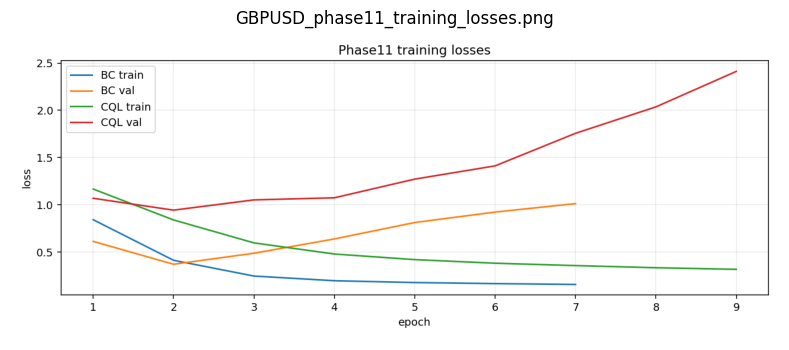

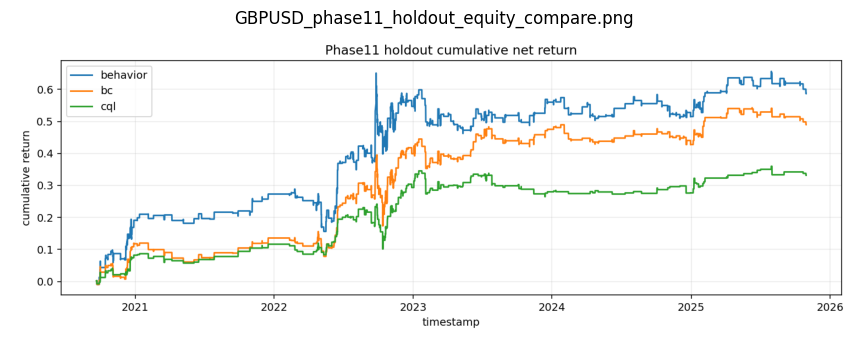

In [3]:
import matplotlib.pyplot as plt

imgs = [
    OUT / 'GBPUSD_phase11_training_losses.png',
    OUT / 'GBPUSD_phase11_holdout_equity_compare.png',
]

for p in imgs:
    img = plt.imread(p)
    plt.figure(figsize=(12, 4))
    plt.imshow(img)
    plt.title(p.name)
    plt.axis('off')
    plt.show()
